# Pattern Shield — Colab prototype
A byte-level transformer for benign / SQL injection / XSS request classification.

**Run:** Upload this notebook to Google Colab. Select a GPU if available, then Run all. CPU fallback works. No API keys, model downloads or dataset accounts are required. All requests are inert text; no network scans are performed.

**Scope:** The default data are synthetic, generated from templates. Results are not production accuracy. Held-out templates test limited generalization, not zero-day detection. A suspicious request does not prove an application vulnerability.

Includes a transformer, TF–IDF baseline, validation-only checkpoint/threshold selection, test and challenge evaluation, notebook demo, log aggregation, export and interview notes. Run and understand it before making claims about results.


## Verification included
All code cells were executed successfully on local CPU with PyTorch 2.14.1+cpu. Model save/load prediction parity passed. These saved outputs are from local execution, not a run in your Google Colab account. Training took 29.5 seconds locally; Colab timing and results can vary. Run all to generate your own measurements.


In [1]:
import importlib.util, subprocess, sys
for module, package in [('torch','torch'),('numpy','numpy'),('pandas','pandas'),
                        ('sklearn','scikit-learn'),('matplotlib','matplotlib'),('joblib','joblib'),('IPython','ipython')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import copy, hashlib, html, json, random, time, zipfile
from pathlib import Path
from urllib.parse import unquote, quote
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LABELS=['benign','sqli','xss']; LABEL_ID={v:i for i,v in enumerate(LABELS)}
MAX_LEN=256; EPOCHS=8; BATCH_SIZE=64
OUT=Path('pattern_shield_results'); OUT.mkdir(exist_ok=True)
print('Device:',DEVICE,'PyTorch:',torch.__version__)


Device: cpu PyTorch: 2.14.1+cpu


## Data and split design
Separate template sets are assigned to train, validation, test and challenge **before** examples are generated. Method, path, encoding and parameter names are sampled independently of class. Canonical duplicates are removed. The challenge includes SQLi/XSS subtypes absent from training, plus difficult benign text.

This controls exact/template leakage but does not eliminate synthetic distribution bias. Requests are short and balanced; real traffic is neither.

**Optional real-data mode:** upload an authorized, de-identified CSV through the Colab Files sidebar; set DATA_CSV below. Columns: text,label,split,group. Labels: benign,sqli,xss. Splits: train,val,test,challenge. Group related sessions or payload families together; no group may cross splits. Each split must contain all three classes. Document source, license and labeling method yourself. Near-duplicate and source/time separation need additional scrutiny.


In [2]:
DATA_CSV=None  # Example: '/content/requests.csv'
TEMPLATES={
'train':{
 'benign':["hello {word}","product {n}","category {word}","page {n}","name O'Reilly {n}","price < {n}","documentation select {word}","email {word}@example.test"],
 'sqli':["' OR {n}={n} -- ","1 UNION SELECT NULL,{n} -- ","' AND {n}={n} #","' OR 'a'='a' /*{n}*/","1; SELECT {n} -- "],
 'xss':["<script>alert({n})</script>","<img src=x onerror=alert({n})>","<svg onload=alert({n})>","<body onload=alert({n})>","<input onfocus=alert({n}) autofocus>"]},
'val':{
 'benign':["sort {word} ascending {n}","user {word} order {n}","learn SQL select count {n}"],
 'sqli':["') OR {n}={n} -- ","0 UNION ALL SELECT {n},NULL -- "],
 'xss':["<script>confirm({n})</script>","<img src=missing onerror=confirm({n})>"]},
'test':{
 'benign':["search for {word} model {n}","support ticket {n} for {word}","how to prevent SQL injection {n}","javascript alert documentation {n}"],
 'sqli':["' OR ({n}={n}) -- ","0 UNION SELECT NULL,NULL,{n} -- "],
 'xss':["<svg onload=confirm({n})>","<script>prompt({n})</script>"]},
'challenge':{
 'benign':["technical article on onerror {word} {n}","SELECT name FROM products tutorial {n}","HTML tag example &lt;script&gt; {n}","union of sets {word} {n}"],
 'sqli':["1 AND SLEEP(2) /*{n}*/","1 AND EXISTS(SELECT 1 FROM users WHERE id={n})","1; WAITFOR DELAY '0:0:2' -- {n}"],
 'xss':['<a href="javascript:confirm({n})">open</a>',"<details open ontoggle=confirm({n})>",'<iframe srcdoc="<script>confirm({n})</script>"></iframe>']}}
def normalize(text):
    # Bounded decoding; preserve case/punctuation. This is not a full HTTP parser.
    value=str(text)[:16384]
    for _ in range(2):
        decoded=html.unescape(unquote(value))
        if decoded==value: break
        value=decoded
    return value
def synthetic_data():
    rng=random.Random(SEED); rows=[]
    for split,count in [('train',500),('val',120),('test',150),('challenge',100)]:
        for label in LABELS:
            for i in range(count):
                templates=TEMPLATES[split][label]; tid=i%len(templates)
                payload=templates[tid].format(n=rng.randint(10,99999),word=rng.choice(['book','blue','phone','alpha','music','coffee']))
                if rng.random()<0.35: payload=quote(payload,safe='')
                method=rng.choice(['GET','POST'])
                path=rng.choice(['/search','/item','/query','/form'])
                param=rng.choice(['q','id','value','input'])
                text=f'{method} {path}?{param}={payload} HTTP/1.1'
                rows.append(dict(text=text,label=label,split=split,group=f'{split}:{label}:{tid}'))
    return pd.DataFrame(rows)
df=pd.read_csv(DATA_CSV) if DATA_CSV else synthetic_data()
DATA_SOURCE='User CSV; document provenance separately' if DATA_CSV else 'Built-in synthetic template-generated requests'
assert {'text','label','split','group'}<=set(df.columns)
assert not df[['text','label','split','group']].isna().any().any(), 'Missing fields'
assert set(df.label)<=set(LABELS)
assert set(df.split)=={'train','val','test','challenge'}
assert (df.groupby('group')['split'].nunique()==1).all(), 'Group leakage'
df['normalized']=df.text.map(normalize)
assert df.normalized.str.strip().ne('').all(), 'Empty requests'
assert df.groupby('normalized').label.nunique().max()==1, 'Conflicting duplicate labels'
order={'train':0,'val':1,'test':2,'challenge':3}
df=df.assign(_order=df.split.map(order)).sort_values('_order').drop_duplicates('normalized').drop(columns='_order').reset_index(drop=True)
parts={s:df[df.split==s].reset_index(drop=True) for s in order}
for s,frame in parts.items():
    assert set(frame.label)==set(LABELS), f'{s} missing classes'
print(DATA_SOURCE); display(pd.crosstab(df.split,df.label))
print('Fraction longer than byte limit:',df.normalized.map(lambda s:len(s.encode('utf-8'))>MAX_LEN).mean())


Built-in synthetic template-generated requests
label      benign  sqli  xss
split                       
challenge     100   100  100
test          150   150  150
train         467   500  500
val           120   120  120
Fraction longer than byte limit: 0.0


In [3]:
# Request-level features; these are NOT behavioral/time-series features.
FEATURE_NAMES=['length','percent_ratio','quote_ratio','angle_ratio','digit_ratio','space_ratio','punct_ratio','entropy']
def features(text):
    raw=str(text)[:16384]; s=normalize(raw); n=max(1,len(s))
    _,counts=np.unique(list(s),return_counts=True)
    p=counts/max(1,counts.sum())
    return [np.log1p(len(raw)),raw.count('%')/max(1,len(raw)),
            (s.count("'")+s.count('"'))/n,(s.count('<')+s.count('>'))/n,
            sum(c.isdigit() for c in s)/n,sum(c.isspace() for c in s)/n,
            sum(not c.isalnum() and not c.isspace() for c in s)/n,
            float(-(p*np.log2(p+1e-12)).sum())]
scaler=StandardScaler().fit(np.array([features(t) for t in parts['train'].text]))
def encode(text):
    bs=normalize(text).encode('utf-8')[:MAX_LEN]
    tokens=np.zeros(MAX_LEN,dtype=np.int64)
    tokens[:len(bs)]=np.frombuffer(bs,dtype=np.uint8).astype(np.int64)+1
    return tokens
class RequestsDataset(Dataset):
    def __init__(self,frame):
        self.x=torch.tensor(np.stack([encode(t) for t in frame.text]),dtype=torch.long)
        self.f=torch.tensor(scaler.transform(np.array([features(t) for t in frame.text])),dtype=torch.float32)
        self.y=torch.tensor(frame.label.map(LABEL_ID).values,dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.x[i],self.f[i],self.y[i]
loaders={s:DataLoader(RequestsDataset(frame),batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=0) for s,frame in parts.items()}


## Architecture and training
UTF-8 bytes → 48-dimensional token + position embeddings → 2 transformer encoder layers with 4 heads each → masked mean pooling → concatenate 8 standardized features → classification head.

Token 0 is padding; bytes 0–255 map to 1–256. Both attention and pooling exclude padding. This is trained from scratch, not BERT. The first 256 bytes reach the transformer: long-request attacks can be missed. Features inspect at most 16,384 characters. A deployment would require HTTP-aware parsing, chunking and an explicit oversized-input policy.

Train with weighted cross-entropy and AdamW. Select checkpoint by validation macro-F1 only. No test/challenge feedback enters training.


In [4]:
class PatternShield(nn.Module):
    def __init__(self):
        super().__init__()
        self.token=nn.Embedding(257,48,padding_idx=0)
        self.position=nn.Embedding(MAX_LEN,48)
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,dropout=0.1,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        # Reinitialize cloned layer matrices independently.
        for block in self.encoder.layers:
            for p in block.parameters():
                if p.dim()>1: nn.init.xavier_uniform_(p)
        self.head=nn.Sequential(nn.LayerNorm(56),nn.Linear(56,32),nn.GELU(),nn.Dropout(0.1),nn.Linear(32,3))
    def forward(self,x,f):
        # Trim all-padding batch tail to avoid wasted quadratic attention work.
        used=max(1,int(x.ne(0).sum(1).max().item()))
        x=x[:,:used]
        mask=x.eq(0)
        h=self.token(x)+self.position(torch.arange(x.size(1),device=x.device))[None,:,:]
        h=self.encoder(h,src_key_padding_mask=mask)
        keep=(~mask).unsqueeze(-1)
        pooled=(h*keep).sum(1)/keep.sum(1).clamp(min=1)
        return self.head(torch.cat([pooled,f],dim=1))
model=PatternShield().to(DEVICE)
print('Parameters:',sum(p.numel() for p in model.parameters()))
@torch.inference_mode()
def probabilities(loader,net=None):
    net=model if net is None else net
    net.eval(); result=[]
    for x,f,y in loader:
        result.append(net(x.to(DEVICE),f.to(DEVICE)).softmax(-1).cpu().numpy())
    return np.concatenate(result)
optimizer=torch.optim.AdamW(model.parameters(),lr=0.001,weight_decay=0.01)
counts=parts['train'].label.value_counts().reindex(LABELS).values
weights=torch.tensor(len(parts['train'])/(3*counts),dtype=torch.float32,device=DEVICE)
criterion=nn.CrossEntropyLoss(weight=weights)
history=[]; best_f1=-1; best_state=None; started=time.perf_counter()
for epoch in range(1,EPOCHS+1):
    model.train(); losses=[]
    for x,f,y in loaders['train']:
        optimizer.zero_grad(set_to_none=True)
        loss=criterion(model(x.to(DEVICE),f.to(DEVICE)),y.to(DEVICE))
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        losses.append(loss.item())
    pred=probabilities(loaders['val']).argmax(1)
    score=f1_score(parts['val'].label.map(LABEL_ID),pred,average='macro')
    history.append({'epoch':epoch,'loss':float(np.mean(losses)),'val_macro_f1':float(score)})
    print(f'Epoch {epoch}/{EPOCHS}: loss={np.mean(losses):.4f}, validation macro-F1={score:.4f}',flush=True)
    if score>best_f1:
        best_f1=score; best_state=copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
TRAIN_SECONDS=time.perf_counter()-started
print('Training seconds:',round(TRAIN_SECONDS,1))


Parameters: 64579
Epoch 1/8: loss=0.8076, validation macro-F1=0.8296
Epoch 2/8: loss=0.2223, validation macro-F1=0.9193
Epoch 3/8: loss=0.0290, validation macro-F1=0.9402
Epoch 4/8: loss=0.0086, validation macro-F1=0.9401
Epoch 5/8: loss=0.0045, validation macro-F1=0.9489
Epoch 6/8: loss=0.0031, validation macro-F1=0.9430
Epoch 7/8: loss=0.0025, validation macro-F1=0.9518
Epoch 8/8: loss=0.0018, validation macro-F1=0.9606
Training seconds: 29.5


In [5]:
# Baseline fit on training only. It may beat the transformer; report that honestly.
baseline=make_pipeline(TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=20000),
                       LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED))
baseline.fit(parts['train'].normalized,parts['train'].label.map(LABEL_ID))
# Alert score = 1 - benign score. Threshold maximizes binary F1 on validation.
vp=probabilities(loaders['val']); vy=parts['val'].label.map(LABEL_ID).to_numpy()
candidates=np.linspace(0.05,0.95,91)
scores=[f1_score(vy!=0,(1-vp[:,0])>=t,zero_division=0) for t in candidates]
THRESHOLD=float(candidates[int(np.argmax(scores))])
print('Validation-selected threshold:',THRESHOLD)
print('Softmax scores are not calibrated probabilities of real-world maliciousness.')


Validation-selected threshold: 0.9299999999999999
Softmax scores are not calibrated probabilities of real-world maliciousness.



TEST
              precision    recall  f1-score   support

      benign       1.00      0.85      0.92       150
        sqli       0.91      1.00      0.95       150
         xss       0.95      1.00      0.97       150

    accuracy                           0.95       450
   macro avg       0.95      0.95      0.95       450
weighted avg       0.95      0.95      0.95       450

Baseline F1: 1.0 Alert FPR: 0.0067 Attack recall: 1.0

CHALLENGE
              precision    recall  f1-score   support

      benign       1.00      0.37      0.54       100
        sqli       0.88      1.00      0.93       100
         xss       0.67      1.00      0.80       100

    accuracy                           0.79       300
   macro avg       0.85      0.79      0.76       300
weighted avg       0.85      0.79      0.76       300

Baseline F1: 0.8869 Alert FPR: 0.52 Attack recall: 1.0
                                                  text  ... false_positive
6    GET /item?q=how%20to%20prevent%2

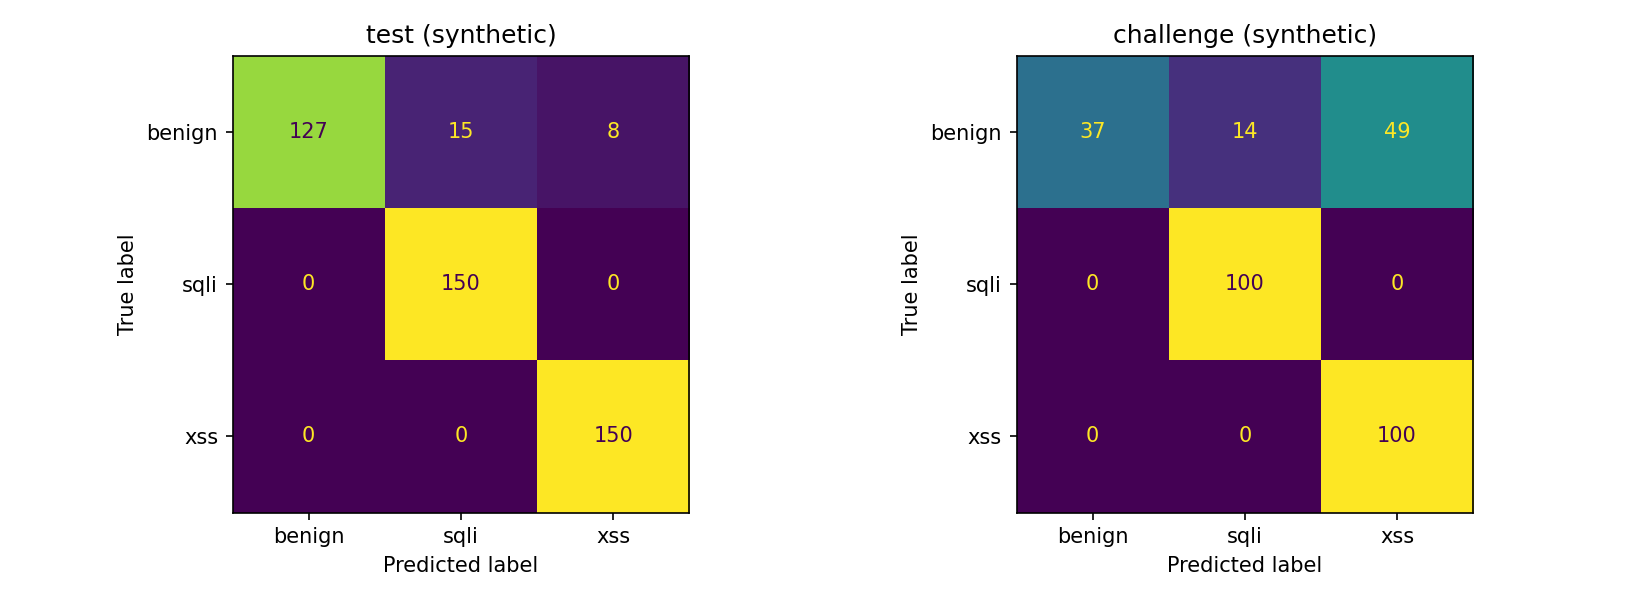

In [6]:
results={}; review_frames=[]
fig,axes=plt.subplots(1,2,figsize=(11,4))
for index,split in enumerate(['test','challenge']):
    frame=parts[split]; y=frame.label.map(LABEL_ID).to_numpy()
    p=probabilities(loaders[split]); pred=p.argmax(1); alert=(1-p[:,0])>=THRESHOLD
    bp=baseline.predict(frame.normalized)
    fpr=float(alert[y==0].mean()); recall=float(alert[y!=0].mean())
    results[split]={'samples':len(frame),'transformer_accuracy':float(accuracy_score(y,pred)),
      'transformer_macro_f1':float(f1_score(y,pred,average='macro')),
      'baseline_macro_f1':float(f1_score(y,bp,average='macro')),
      'binary_alert_false_positive_rate':fpr,'binary_alert_attack_recall':recall,
      'classification_report':classification_report(y,pred,labels=[0,1,2],target_names=LABELS,output_dict=True,zero_division=0)}
    print('\n'+split.upper())
    print(classification_report(y,pred,labels=[0,1,2],target_names=LABELS,zero_division=0))
    print('Baseline F1:',round(results[split]['baseline_macro_f1'],4),'Alert FPR:',round(fpr,4),'Attack recall:',round(recall,4))
    ConfusionMatrixDisplay(confusion_matrix(y,pred,labels=[0,1,2]),display_labels=LABELS).plot(ax=axes[index],colorbar=False)
    axes[index].set_title(split+(' (synthetic)' if not DATA_CSV else ''))
    review=frame[['text','label','split','group']].copy()
    review['predicted']=[LABELS[i] for i in pred]; review['attack_score']=1-p[:,0]; review['alert']=alert
    review['classification_error']=pred!=y; review['false_positive']=(y==0)&alert
    review_frames.append(review)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=150); plt.show()
review=pd.concat(review_frames,ignore_index=True)
display(review[review.classification_error|review.false_positive].head(15))
review.to_csv(OUT/'predictions.csv',index=False)


## Try request strings
Edit the demo list and rerun. Inputs are never executed or sent to servers. The three-class argmax and the binary alert policy may disagree because they answer different questions. Low confidence is a heuristic, **not** a reliable novelty detector.


In [7]:
@torch.inference_mode()
def predict_requests(texts):
    if isinstance(texts,str): texts=[texts]
    if not texts or any(not isinstance(t,str) or not t.strip() for t in texts):
        raise ValueError('Provide non-empty request strings.')
    frame=pd.DataFrame({'text':texts,'label':['benign']*len(texts)})
    p=probabilities(DataLoader(RequestsDataset(frame),batch_size=BATCH_SIZE))
    rows=[]
    for text,probs in zip(texts,p):
        rows.append({'request':text,'predicted_class':LABELS[int(probs.argmax())],
         'attack_score':round(float(1-probs[0]),4),'alert':bool(1-probs[0]>=THRESHOLD),
         'low_confidence':bool(probs.max()<0.6),
         'truncated':len(normalize(text).encode('utf-8'))>MAX_LEN,
         **{f'score_{label}':round(float(probs[i]),4) for i,label in enumerate(LABELS)}})
    return pd.DataFrame(rows)
DEMO_REQUESTS=[
 'GET /search?q=wireless+keyboard HTTP/1.1',
 "GET /item?id=1' OR 9=9 -- HTTP/1.1",
 'GET /search?q=<script>alert(7)</script> HTTP/1.1',
 'GET /search?q=how to prevent SQL injection HTTP/1.1',
 'GET /item?id=1 AND SLEEP(2) HTTP/1.1']
display(predict_requests(DEMO_REQUESTS))


                                             request  ... score_xss
0           GET /search?q=wireless+keyboard HTTP/1.1  ...    0.0009
1                 GET /item?id=1' OR 9=9 -- HTTP/1.1  ...    0.0005
2   GET /search?q=<script>alert(7)</script> HTTP/1.1  ...    0.9980
3  GET /search?q=how to prevent SQL injection HTT...  ...    0.0007
4               GET /item?id=1 AND SLEEP(2) HTTP/1.1  ...    0.0005

[5 rows x 9 columns]


In [8]:
# Separate behavioral enrichment: rules over client/minute counts, NOT learned behavior.
def summarize_logs(logs):
    needed={'timestamp','client','text','path'}
    if not needed<=set(logs): raise ValueError(f'Required columns: {needed}')
    scored=predict_requests(logs.text.tolist()).drop(columns='request')
    enriched=pd.concat([logs.reset_index(drop=True),scored],axis=1)
    enriched['minute']=pd.to_datetime(enriched.timestamp,utc=True).dt.floor('min')
    summary=enriched.groupby(['client','minute']).agg(requests=('text','size'),
               alerts=('alert','sum'),distinct_paths=('path','nunique')).reset_index()
    summary['review_burst']=(summary.requests>=20)|(summary.alerts>=5)
    return enriched,summary
logs=pd.DataFrame([{'timestamp':f'2026-01-01T10:00:{i:02d}Z','client':'lab-client',
 'path':'/search','text':DEMO_REQUESTS[i%len(DEMO_REQUESTS)]} for i in range(25)])
enriched,behavior=summarize_logs(logs); display(behavior)
behavior.to_csv(OUT/'behavior_summary.csv',index=False)


       client                    minute  ...  distinct_paths  review_burst
0  lab-client 2026-01-01 10:00:00+00:00  ...               1          True

[1 rows x 6 columns]


In [9]:
# Export model, scaler, baseline, data, actual metrics, report and provenance.
checkpoint={'state_dict':{k:v.cpu() for k,v in model.state_dict().items()},
            'max_len':MAX_LEN,'labels':LABELS,'threshold':THRESHOLD,'seed':SEED}
torch.save(checkpoint,OUT/'pattern_shield.pt')
joblib.dump(scaler,OUT/'feature_scaler.joblib'); joblib.dump(baseline,OUT/'baseline.joblib')
loaded=torch.load(OUT/'pattern_shield.pt',map_location=DEVICE,weights_only=True)
restored=PatternShield().to(DEVICE); restored.load_state_dict(loaded['state_dict'])
checkloader=DataLoader(RequestsDataset(pd.DataFrame({'text':DEMO_REQUESTS,'label':['benign']*len(DEMO_REQUESTS)})),batch_size=BATCH_SIZE)
assert np.allclose(probabilities(checkloader),probabilities(checkloader,restored),atol=1e-5), 'Reload mismatch'
manifest={'data_source':DATA_SOURCE,'seed':SEED,'max_len':MAX_LEN,'epochs':EPOCHS,
 'training_seconds':TRAIN_SECONDS,'threshold':THRESHOLD,'feature_names':FEATURE_NAMES,
 'torch':torch.__version__,'numpy':np.__version__,
 'dataset_sha256':hashlib.sha256(df.to_csv(index=False).encode()).hexdigest(),
 'split_counts':df.split.value_counts().to_dict(),
 'limits':['Synthetic default data','No production validation','Not a scanner','No zero-day guarantee','Uncalibrated scores','Truncation risk']}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
(OUT/'metrics.json').write_text(json.dumps(results,indent=2))
pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
df.to_csv(OUT/'dataset.csv',index=False)
report=['# Pattern Shield evaluation report',f'Data: {DATA_SOURCE}',
        f'Training seconds: {TRAIN_SECONDS:.1f}',f'Validation-selected threshold: {THRESHOLD:.3f}','## Results']
for split,r in results.items():
    report.append(f"{split}: transformer macro-F1={r['transformer_macro_f1']:.4f}; baseline macro-F1={r['baseline_macro_f1']:.4f}; alert FPR={r['binary_alert_false_positive_rate']:.4f}; attack recall={r['binary_alert_attack_recall']:.4f}")
report.extend(['## Interpretation','Dataset-specific measurements; not production accuracy or proof of zero-day detection.',
 '## Triage','Flagged requests are investigation leads, not confirmed vulnerabilities. Validate application behavior in an authorized test environment.',
 '## Remediation','SQLi: parameterized queries and least-privilege database accounts. XSS: context-aware output encoding, safe DOM APIs and suitable sanitization; CSP as defense in depth.',
 'CWE-89 and CWE-79 describe the weakness classes. ATT&CK T1190 is conditional on exploitation context, not an automatic payload label.',
 '## Reproduce','Use this notebook, saved dataset and manifest. Only load trusted model/joblib files.'])
(OUT/'report.md').write_text('\n\n'.join(report))
with zipfile.ZipFile('pattern_shield_results.zip','w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.iterdir()): z.write(p,arcname=p.name)
print('Model save/load parity: PASS. Saved pattern_shield_results.zip')
DOWNLOAD_RESULTS=False  # Set True in Colab, or download ZIP through its Files sidebar.
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download('pattern_shield_results.zip')


Model save/load parity: PASS. Saved pattern_shield_results.zip


## Interview preparation
**A truthful explanation after you run and understand the notebook:**

“Pattern Shield is a Colab prototype that classifies request text as benign, SQL injection or XSS. It uses byte embeddings and a small transformer encoder, combined with eight statistical features. I compare it against a character TF–IDF logistic-regression baseline. Templates are separated across training, validation and testing; the checkpoint and alert threshold use validation data only. I review false positives and held-out-template failures. The default data are synthetic, so these scores do not establish production accuracy or zero-day detection.”

If asked about development, acknowledge AI assistance and specify what you personally ran, changed and validated. Do not imply previous deployments or months of research that did not happen.

| Likely question | Answer |
|---|---|
| Why a transformer? | Self-attention can learn relations between byte positions. Whether it beats simpler methods must be measured. |
| What is attention? | softmax(QKᵀ / √dₖ)V: queries compare against keys to weight value vectors. Multiple heads learn different relationships. |
| Why bytes? | Fixed vocabulary handles punctuation/encoding without unknown-word tokens; the tradeoff is longer sequences. |
| What encodes position? | A trainable 256-position embedding added to byte embeddings. |
| What is the loss and optimizer? | Class-weighted cross-entropy and AdamW, with gradient clipping and validation checkpoint selection. |
| What features? | Length, percent/quote/angle/digit/space/punctuation ratios and character entropy; scaler fits training only. |
| What prevents leakage? | Disjoint template groups, canonical deduplication, train-only fitting and validation-only selection. Real traffic also needs source/session/time separation and stronger near-duplicate checks. |
| Why macro-F1? | It weights each class equally; accuracy can hide minority-class failures. Also report per-class precision/recall and alert FPR. |
| Precision versus recall? | Precision = TP/(TP+FP), recall = TP/(TP+FN), FPR = FP/(FP+TN). |
| How choose threshold? | Maximize binary validation F1 in this demo. Production needs representative prevalence and a false-positive budget. |
| Does 0.95 mean 95% attack probability? | No: uncalibrated softmax scores. Calibration requires separate representative validation. |
| Unseen attacks? | Held-out templates/subtypes test limited generalization. Zero-day detection is not established. |
| Behavioral analysis? | A separate rules-based aggregation counts requests, alerts and paths per client/minute. It is not a trained behavior model. |
| Is it a vulnerability scanner? | No. Offline request classification; no asset discovery or proof of server-side exploitability. |
| MITRE mapping? | CWE-89 for SQLi and CWE-79 for XSS. ATT&CK T1190 is contextual, only where exploitation of a public-facing application is established. |
| What if baseline wins? | Report it honestly. Simpler models may be better for small datasets and tight latency budgets. |
| Biggest limitations? | Synthetic bias, short context, imperfect decoding, no response context, uncalibrated scores and no production validation. |
| Next steps? | Real authorized data, audited labels, time/source split, HTTP-aware parsing, calibration, drift monitoring and shadow-mode testing. |

### Five-minute demonstration
1. Show data counts and explain synthetic provenance.
2. Explain the model and masks.
3. Show transformer versus baseline results and confusion matrices.
4. Try benign and malicious strings; show a mistake or ambiguous case.
5. Show challenge performance, exported report and limitations.

### What the original resume bullets overstate
- **Previously unseen attacks:** only held-out-template generalization is evaluated.
- **Web traffic datasets:** default data are synthetic, not captured production traffic.
- **Automated discovery scans:** not implemented.
- **Behavioral analysis:** simple log aggregation rules, not learned behavior.
- **PoC reporting:** an evaluation/triage report, not a confirmed exploitation PoC.

A strong interviewer will test these distinctions. Do not defend capabilities you have not implemented and verified.

### Troubleshooting
- No GPU: CPU fallback is automatic. Training may take longer.
- CUDA out of memory: reduce BATCH_SIZE to 16 and rerun all.
- CSV assertion: repair schema/groups/classes; do not delete leakage checks.
- Low challenge score: report the limitation. Do not tune on it while still calling it an untouched test.
- Colab disconnect: runtime files are temporary; download the ZIP and save notebook outputs.

### References
- [PyTorch TransformerEncoder](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [MITRE ATT&CK T1190](https://attack.mitre.org/techniques/T1190/)

